# 02. Data Analysis & Visualization
descrizione

### Indice Capitoli
- **Prefazione: Data Loading** Caricamento dei 13 dataset e verifica dtypes.
- **Capitolo 1: Analisi Temporale**
- **Capitolo 2: Analisi Geografica**

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
%load_ext autoreload
%autoreload 2
from functions.utils import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


##  Prefazione: Data Loading

In questa sezione vengono caricati i dataset già puliti
e preparati nel notebook precedente. L’obiettivo è rendere i dati
pronti per l’analisi e garantire che i tipi di dato (dtypes) siano
corretti e coerenti.  
Alcune operazioni di conversione dei tipi di dato erano già state effettuate
nel notebook precedente; tuttavia, poiché Pandas non mantiene i tipi al
riaprirsi del file, le conversioni dovranno essere eseguite nuovamente.

In [2]:
characters_df = pd.read_csv("../data/processed/Characters_cleaned.csv")
character_anime_works_df = pd.read_csv("../data/processed/Character_anime_works_cleaned.csv")
character_nicknames_df = pd.read_csv("../data/processed/Character_nicknames_cleaned.csv")
details_df = pd.read_csv("../data/processed/Details_cleaned.csv")
favs_df = pd.read_csv("../data/processed/Favs_cleaned.csv")
person_alternate_names_df = pd.read_csv("../data/processed/Person_alternate_names_cleaned.csv")
person_anime_works_df = pd.read_csv("../data/processed/Person_anime_works_cleaned.csv")
person_voice_works_df = pd.read_csv("../data/processed/Person_voice_works_cleaned.csv")
person_details_df = pd.read_csv("../data/processed/Person_details_cleaned.csv")
profiles_df = pd.read_csv("../data/processed/Profiles_cleaned.csv")
ratings_df = pd.read_csv("../data/processed/Ratings_cleaned.csv")
recommendations_df = pd.read_csv("../data/processed/Recommendations_cleaned.csv")
stats_df = pd.read_csv("../data/processed/Stats_cleaned.csv")

In [3]:
datasets = {
    "Characters": characters_df,
    "Character_anime_works": character_anime_works_df,
    "Character_nicknames": character_nicknames_df,
    "Details": details_df,
    "Favs": favs_df,
    "Person_alternate_names": person_alternate_names_df,
    "Person_anime_works": person_anime_works_df,
    "Person_voice_works": person_voice_works_df,
    "Person_details": person_details_df,
    "Profiles": profiles_df,
    "Ratings": ratings_df,
    "Recommendations": recommendations_df,
    "Stats": stats_df
}

Le colonne contenenti date vengono convertite in
tipo `datetime` per consentire operazioni temporali corrette.

In [4]:
datasets["Person_details"] = convert_to_datetime(datasets["Person_details"], "birthday")
datasets["Profiles"] = convert_to_datetime(datasets["Profiles"], "joined")
datasets["Profiles"] = convert_to_datetime(datasets["Profiles"], "birthday")
datasets["Details"] = convert_to_datetime(datasets["Details"], "start_date")
datasets["Details"] = convert_to_datetime(datasets["Details"], "end_date")

c:\Users\ASUS\Desktop\SaraZunino\solution\functions\utils.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[column_name] = pd.to_datetime(df[column_name], errors='coerce', format='%Y').fillna(


Column 'birthday' successfully converted.
Column 'joined' successfully converted.
Column 'birthday' successfully converted.
Column 'start_date' successfully converted.
Column 'end_date' successfully converted.


c:\Users\ASUS\Desktop\SaraZunino\solution\functions\utils.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[column_name] = pd.to_datetime(df[column_name], errors='coerce', format='%Y').fillna(
c:\Users\ASUS\Desktop\SaraZunino\solution\functions\utils.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[column_name] = pd.to_datetime(df[column_name], errors='coerce', format='%Y').fillna(


Le colonne numeriche che contengono solo valori interi ma includono
  valori NaN vengono convertite in `Int64` (tipo intero
  compatibile con NaN), evitando così che siano trattate come float64.

In [5]:
datasets["Details"]["year"] = datasets["Details"]["year"].astype("Int64")
datasets["Details"]["scored_by"] = datasets["Details"]["scored_by"].astype("Int64")
datasets["Details"]["rank"] = datasets["Details"]["rank"].astype("Int64")
datasets["Details"]["episodes"] = datasets["Details"]["episodes"].astype("Int64")
datasets["Characters"]["favorites"] = datasets["Characters"]["favorites"].astype("Int64")

cols_to_fix = ['watching', 'completed', 'on_hold', 'dropped', 'plan_to_watch']
for col in cols_to_fix:
    if col in datasets["Profiles"].columns:
        datasets["Profiles"][col] = datasets["Profiles"][col].astype("Int64")

## Capitolo 1: Evoluzione Temporale del Mondo degli Anime

L’animazione giapponese ha conosciuto una crescita significativa nel corso del XX e XXI secolo.    
Per questa analisi sono stati considerati solo gli anime narrativi principali, escludendo titoli di tipo *Music*, *CM* (Commercials) e *PV* (Promotional Videos).  
I dati relativi al 2026 non sono stati presi in considerazione poiché parziali e non significativi.

### 1.1 Evoluzione della Produzione Anime Annuale 


Il grafico mostra l'andamento del numero di anime prodotti ogni anno. 


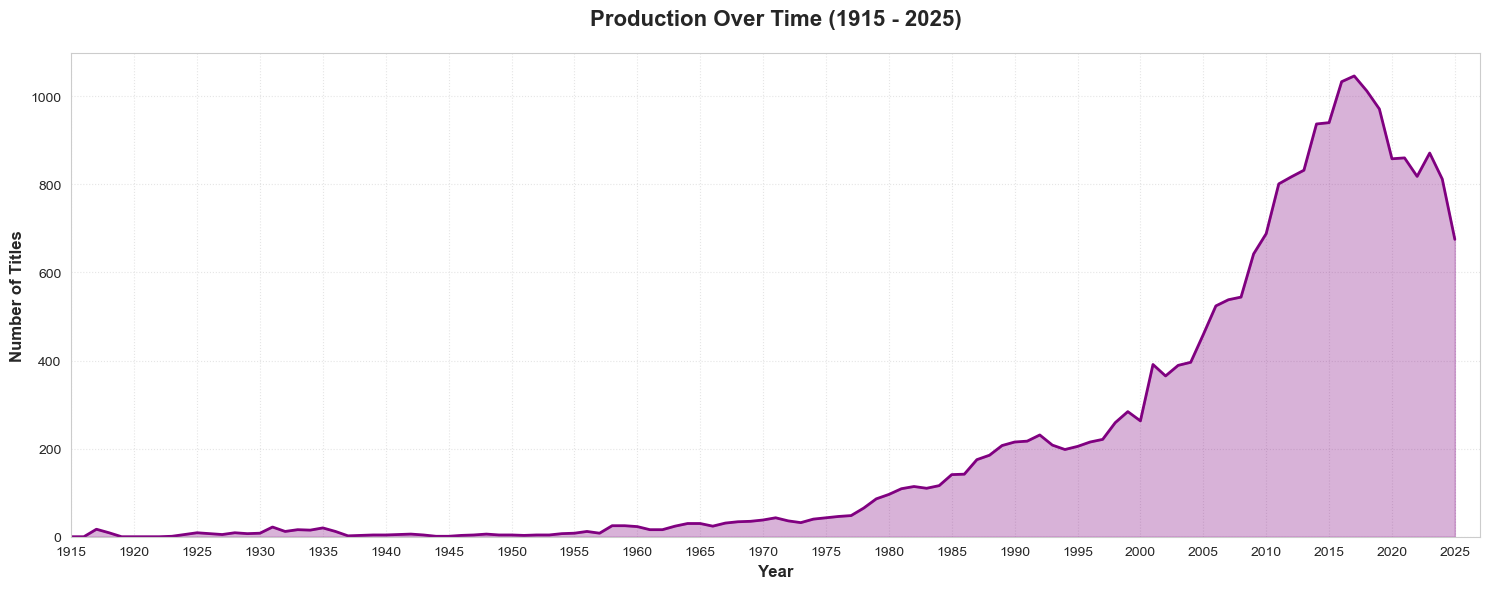

In [107]:
plot_yearly_production(details_df)

- **Dal 1915 al 1955 – Le origini**  
In questo periodo la produzione di anime era quasi nulla, con 0, massimo 2 titoli all’anno. Gli anime erano cortometraggi sperimentali  
destinati principalmente ai cinema. La televisione non era ancora diffusa, quindi non esistevano serie TV come quelle che conosciamo oggi.

- **Dal 1956 al 1975 – I primi passi**  
L’avvento della televisione favorisce la nascita dei primi anime per il piccolo schermo. La produzione annua cresce e nascono opere  
iconiche come *Lupin III*, *Rocky Joe* e *Heidi* che che contribuiscono ad attirare sempre più l’interesse del pubblico e a stimolare la produzione di anime televisivi.

- **Dal 1976 al 2000 – La crescita**  
La produzione accelera sensibilmente, questo periodo vede la nascita di grandi franchise come *Dragon Ball*, *One Piece*, *Neon Genesis   
Evangelion* e *Cowboy Bebop*. Gli anime diventano un fenomeno culturale globale e la produzione annuale aumenta rapidamente.

- **Dal 2001 al 2017 – Il boom**  
Il numero di titoli prodotti ogni anno cresce esponenzialmente, raggiungendo il suo picco massimo intorno al 2017. Alcuni titoli rappresentativi   
di questo periodo sono *Attack on Titan*, *One Punch Man* e *My Hero Academia*. La nascita delle piattaforme streaming come Netflix e CrunchyRoll accelerano ulteriormente la produzione e la diffusione degli anime.

- **Dal 2018 ad oggi – Il mercato maturo**  
Negli anni più recenti la produzione segna un calo rispetto agli anni precedenti. Questo riflette un mercato ormai saturo e competitivo,  
dove gli studios selezionano con più attenzione i progetti per evitare rischi finanziari.

**Analisi Complessiva**  
L’evoluzione della produzione anime mostra tre fasi principali: una fase iniziale lenta, una crescita rapida e un periodo di discesa recente. La crescita è stata favorita dalla televisione, dall’espansione internazionale e dalle innovazioni tecnologiche nell’animazione digitale. Negli ultimi anni la discesa della produzione indica un mercato competitivo dove gli studios prestano maggiore attenzione alla qualità rispetto alla quantità.


### 1.2 Distribuzione della Produzione Anime per Fonte

Il grafico mostra la suddivisione degli anime prodotti in base alla loro fonte originale.  
La categoria `Unknown` è stata esclusa, in quanto non rilevante ai fini dell’analisi.  

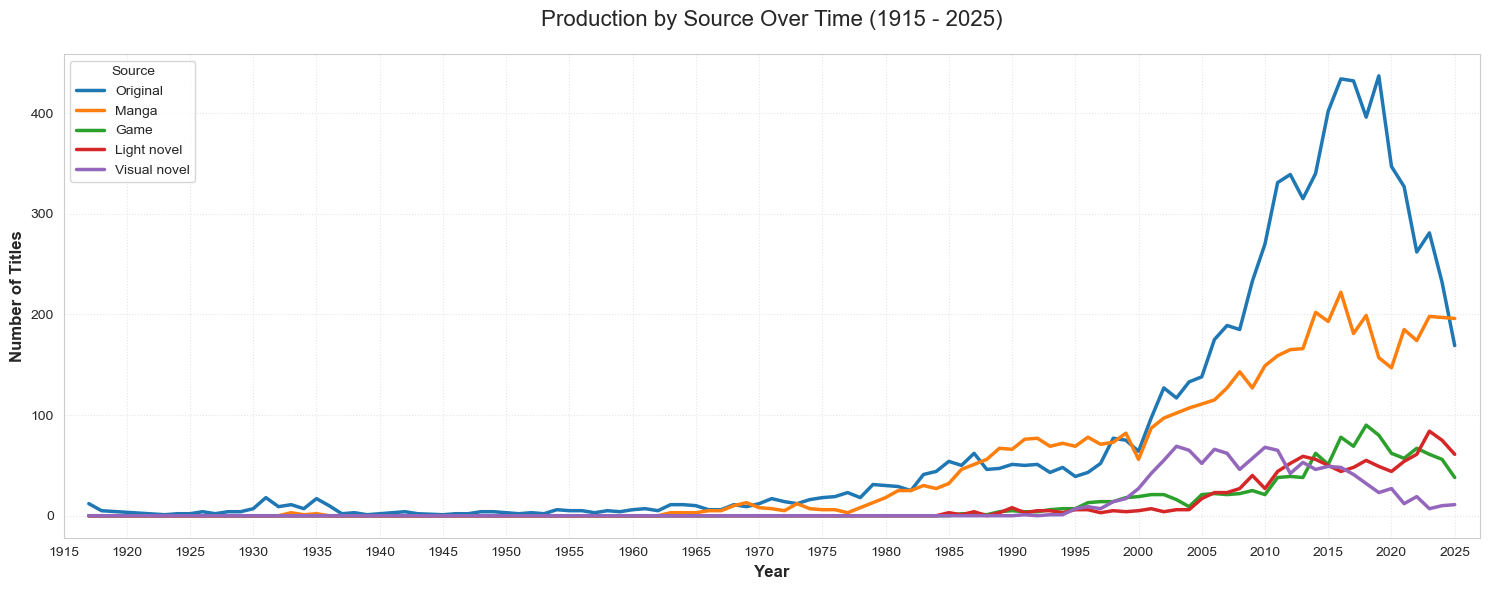

In [106]:
plot_production_by_source(details_df)

- **I primi anni**  
Nei primi lavori di animazione, la maggior parte degli anime erano *original*, mentre gli adattamenti da *manga* erano pochi. Fino al 1965  
circa, gli anime original dominavano perché erano più semplici da produrre e permettevano agli studi di sperimentare nuovi stili e format  
televisivi. Gli adattamenti da *manga* erano limitati perché i *manga* pubblicati e popolari era ancora ristretta.

- **La crescita degli adattamenti Manga**  
Dal 1965 in poi si inizia a produrre più anime tratti da manga rispetto al passato. Gli *original* continuano a essere numerosi,  
ma a partire dalla seconda metà degli anni ’80 i *manga* li superano grazie alla loro capacità di attrarre una fanbase già consolidata,  
ciò riduce i rischi per gli studios. 
 
- **La rapida ascesa degli Original**  
Dopo il 2000, si osserva una grande crescita degli anime *original*, favorita dalla nascita di piattaforme streaming e e digitali.   
Questi canali permettono agli studios di raggiungere un pubblico globale senza dipendere dai franchise già esistenti. Gli *original*   
offrono più libertà creativa e l’opportunità di lanciare nuovi franchise, motivo per cui la loro produzione cresce rapidamente rispetto al passato.

- **Trend degli Original e Manga**   
Gli anime *original* mostrano una crescita più rapida, ma anche un calo altrettanto veloce negli ultimi anni, mentre gli adattamenti da   
*manga* seguono una linea in crescita più stabile. 

- **Altre fonti popolari: Giochi, Light Novel e Visual Novel**  
A partire dagli anni 2000, cresce la produzione di anime tratti da *giochi*, *light novel* e *visual novel*. Le *visual novel* hanno visto   
un calo costante negli ultimi anni; al contrario le *light novel* registrano una crescita costante grazie a serie di successo come *Sword Art Online* e *Re:Zero*.

**Analisi Complessiva**  
La distribuzione annuale della produzione anime per fonte evidenzia la predominanza degli *original* e degli adattamenti da *manga*. Gli *original*   
superano numericamente di gran lunga le altre categorie, ma la maggior parte dei grandi successi proviene principalmente dai *manga*,  
come *Attack on Titan*, *Death Note* e *Naruto*. 

### Analisi della popolarità e valutazione annuale

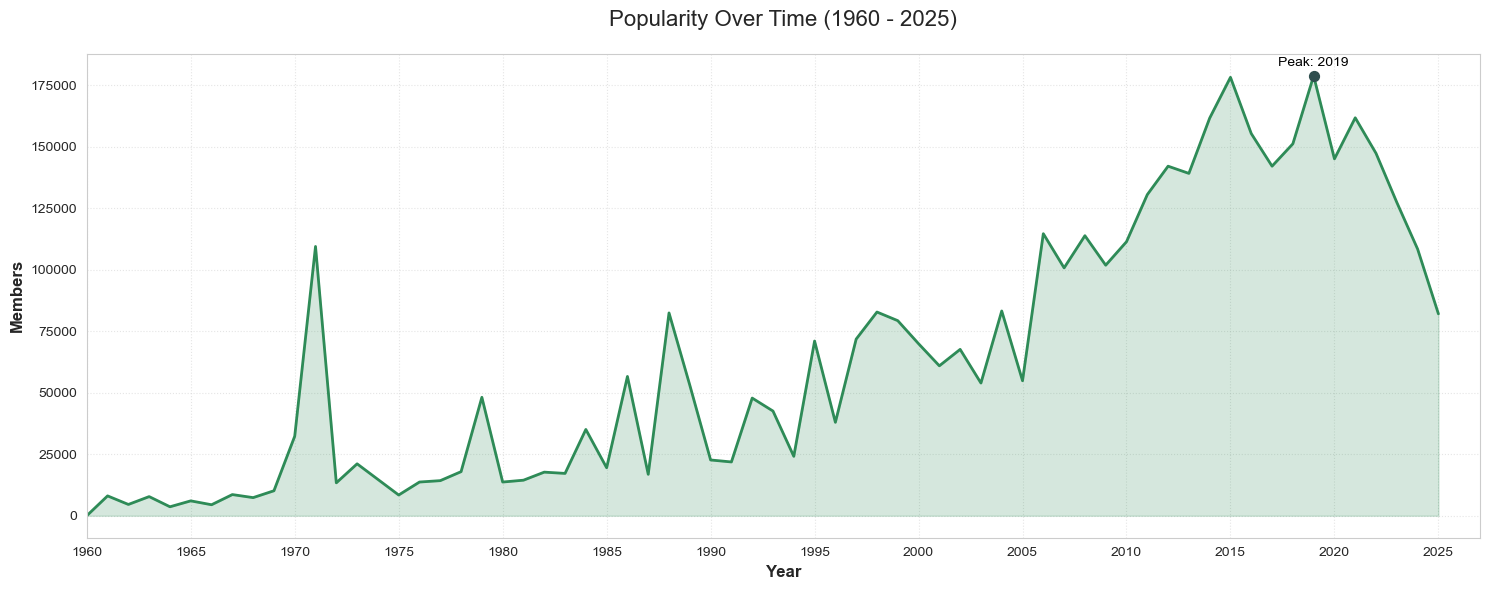

In [97]:
plot_popularity(details_df)

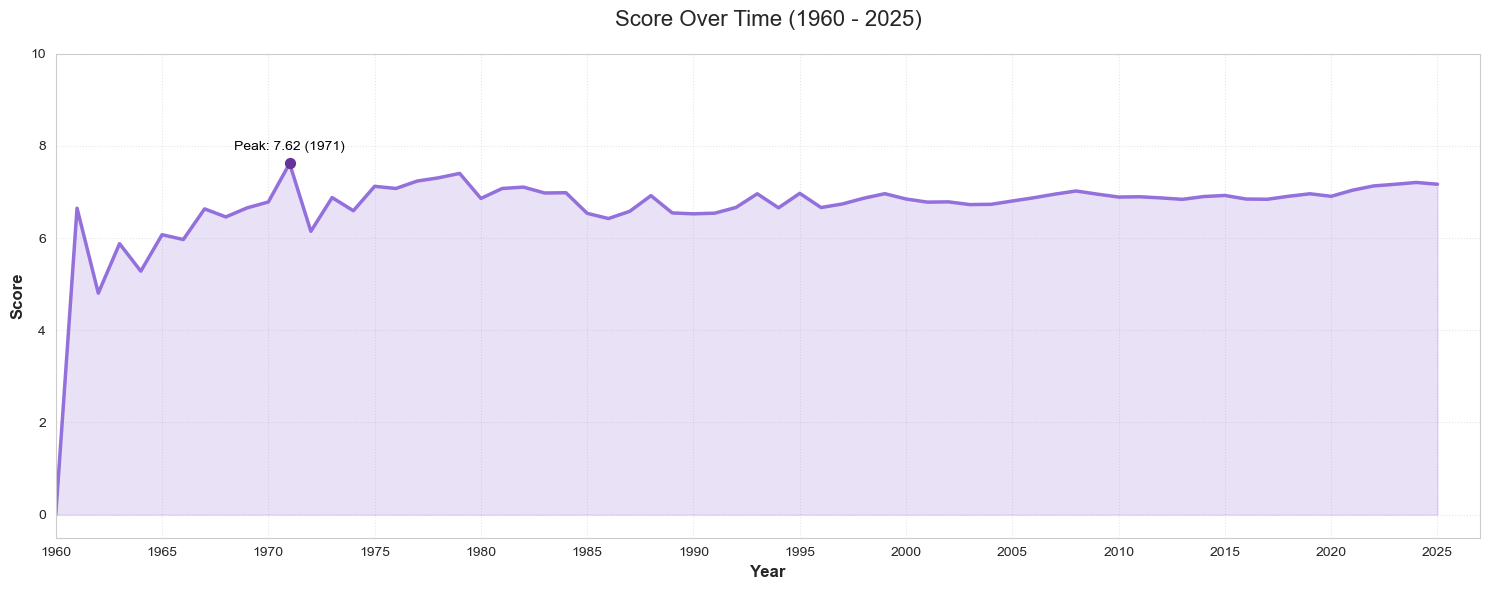

In [92]:
plot_score(details_df)

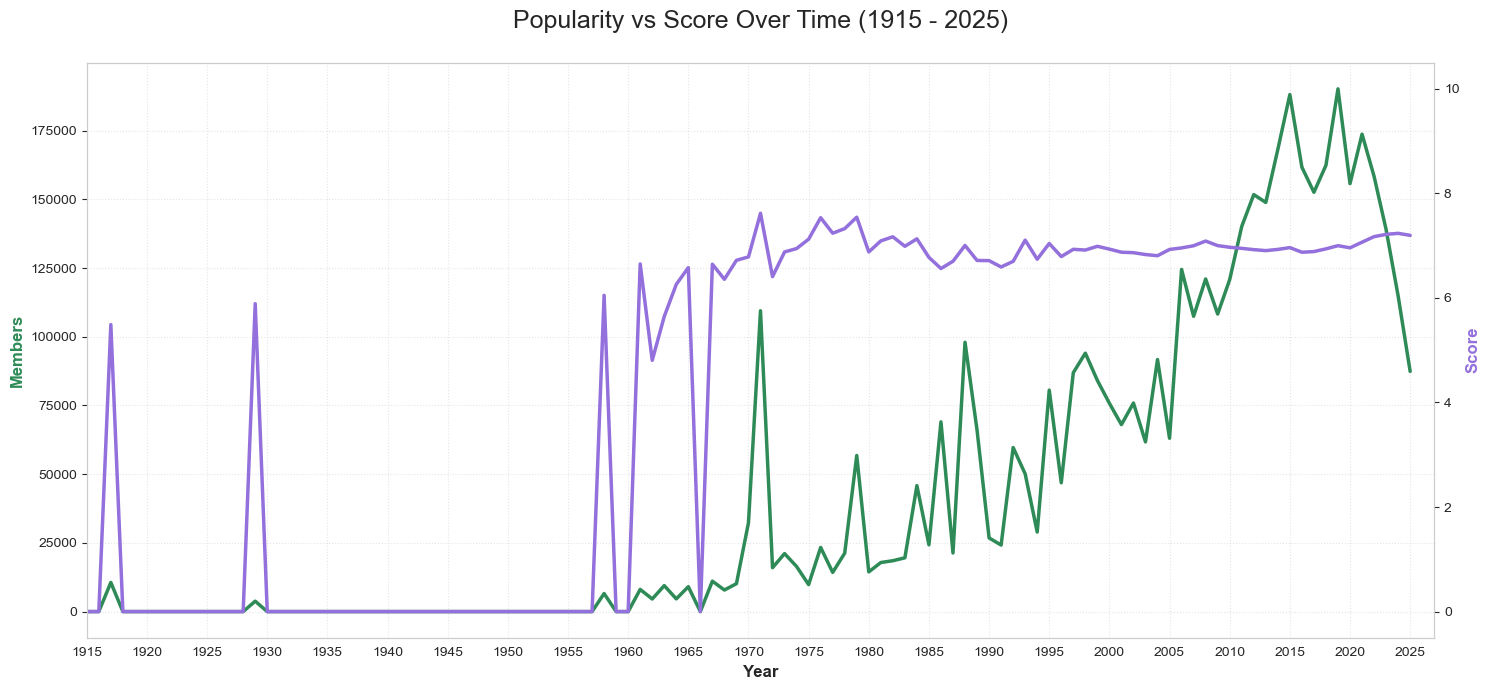

In [68]:
plot_popularity_vs_score(details_df)

### 1.4 Andamento del Numero Medio di Episodi

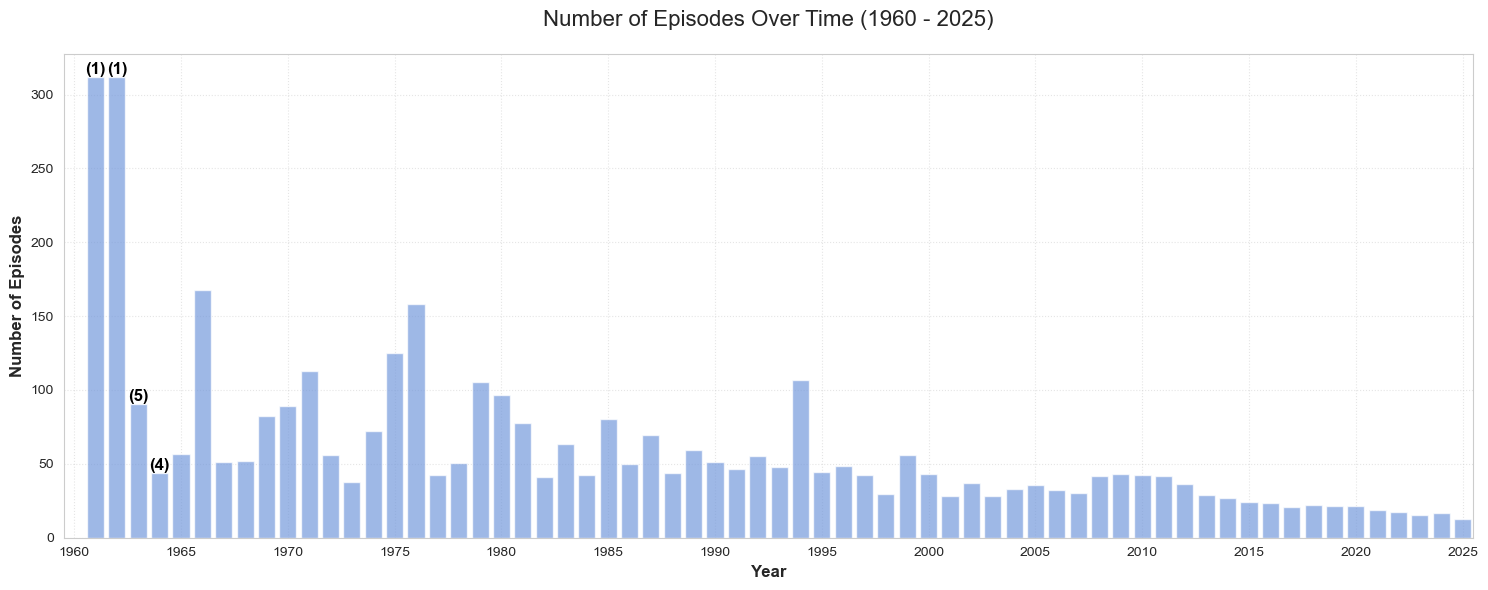

In [34]:
plot_episodes(details_df)

### Analisi Stagionalità

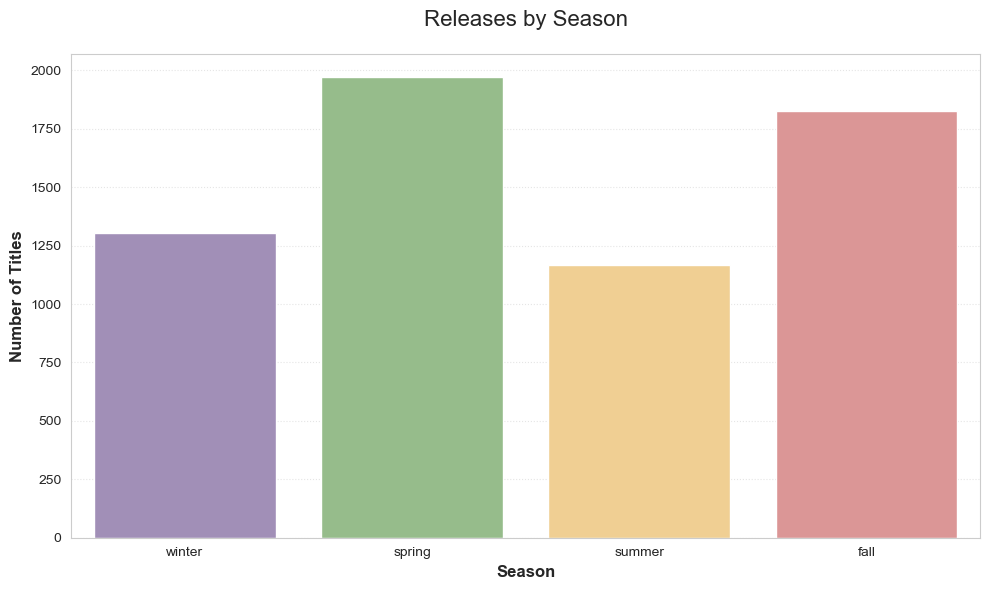

In [35]:
plot_season(details_df)